# LAB 02 — K-Nearest Neighbors: từ khoảng cách đến quyết định


**DNU Learning Analytics Lab**


- **Họ tên:** Lê Trung Kiên
- **MSSV:** 1771020404
- **Lớp:** CNTT18-02


> **Câu hỏi trung tâm:** KNN đưa ra dự đoán dựa trên “hàng xóm” như thế nào, và điều gì làm thay đổi những hàng xóm đó?
>- Trong bài toán phân loại, KNN biểu diễn mỗi đối tượng bằng một vector đặc trưng. Với mẫu mới, thuật toán tính khoảng cách đến các mẫu trong tập huấn luyện, sắp xếp theo khoảng cách tăng dần, chọn K mẫu gần nhất (các “hàng xóm”), rồi dự đoán nhãn có nhiều phiếu nhất trong nhóm đó. Ví dụ, với K=3, nếu hai hàng xóm thuộc lớp cần hỗ trợ và một hàng xóm thuộc lớp không cần hỗ trợ thì dự đoán là cần hỗ trợ.
Những yếu tố làm thay đổi tập hàng xóm gồm:
>- **Số hàng xóm K:** thay đổi số điểm được chọn để bỏ phiếu; K nhỏ nhạy với nhiễu, K lớn xét vùng rộng hơn và có thể làm mờ cấu trúc cục bộ. Khi dữ liệu và cách đo giữ nguyên, đổi K không làm đổi thứ tự khoảng cách.
>- **Hàm khoảng cách:** Euclidean và Manhattan đo độ gần khác nhau nên có thể làm đổi thứ tự các điểm. Trong ví dụ của bài, Euclidean chọn A, B, C và dự đoán Class A; Manhattan chọn A, D, E và dự đoán Class B.
>- **Chuẩn hóa và lựa chọn đặc trưng:** biến có thang đo lớn có thể chi phối khoảng cách. Scaling, thêm/bớt đặc trưng hoặc thay đổi trọng số đặc trưng sẽ thay đổi đóng góp của từng chiều, từ đó có thể đổi hàng xóm. Scaler phải được fit chỉ trên tập train.
>- **Dữ liệu huấn luyện và mẫu cần dự đoán:** thay đổi các điểm train hoặc giá trị đặc trưng của mẫu mới cũng có thể thay đổi nhóm điểm gần nhất.
>- Vì vậy, dự đoán của KNN phụ thuộc vào cách định nghĩa “gần” và nhóm hàng xóm được chọn. Hàng xóm thay đổi không nhất thiết làm nhãn dự đoán thay đổi nếu nhãn đa số vẫn giữ nguyên.

Lab bắt đầu bằng bài toán A/B tổng quát rồi mới quay lại `StudentPerformanceFactors`, để nhấn mạnh KNN là thuật toán tổng quát.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from knn_manual import euclidean_distance, manhattan_distance, get_k_neighbors, knn_predict_one
DATA_PATH = Path('data/StudentPerformanceFactors.csv')
print('Environment ready! Dataset exists:', DATA_PATH.exists())

Environment ready! Dataset exists: True


# Mission 1 — Distance first: “gần” nghĩa là gì?

Với `A=(3,3)` và `B=(5,5)`, hãy tính bằng tay Euclidean và Manhattan distance rồi hoàn thiện hai hàm tương ứng trong `knn_manual.py`.

**Trả lời**

- Euclidean = √((3−5)² + (3−5)²) = √8 = 2√2 ≈ **2,8284**.
- Manhattan = |3−5| + |3−5| = 2 + 2 = **4**.

Euclidean đo khoảng cách đường thẳng; Manhattan cộng độ lệch tuyệt đối theo từng trục.

In [2]:
A, B = [3,3], [5,5]
for name, fn in [('Euclidean', euclidean_distance), ('Manhattan', manhattan_distance)]:
    try:
        print(name, '=', fn(A, B))
    except NotImplementedError as e:
        print(name, '-> TODO:', e)

Euclidean = 2.8284271247461903
Manhattan = 4.0


## Tình huống đổi metric thì đổi prediction


Với `sample=(5,5)`, `K=3` và năm điểm A–E dưới đây, chỉ đổi Euclidean sang Manhattan có thể làm nhãn dự đoán đổi mà không hòa phiếu. Hãy dự đoán trước khi chạy code.


| Điểm | x1 | x2 | Nhãn |
|---|---:|---:|---|
| A | 6 | 6 | Class A |
| B | 8 | 8 | Class A |
| C | 2 | 8 | Class A |
| D | 5 | 10 | Class B |
| E | 10 | 5 | Class B |


**Trả lời**

| Điểm | Euclidean đến (5,5) | Manhattan đến (5,5) |
|---|---:|---:|
| A | √2 ≈ 1,414 | 2 |
| B | √18 ≈ 4,243 | 6 |
| C | √18 ≈ 4,243 | 6 |
| D | 5 | 5 |
| E | 5 | 5 |

- Euclidean: ba hàng xóm A, B, C đều thuộc Class A → **Class A (3/3 phiếu)**.
- Manhattan: ba hàng xóm A, D, E có hai điểm thuộc Class B → **Class B (2/3 phiếu)**.

Đổi metric làm đổi thứ tự khoảng cách và tập hàng xóm nên dự đoán thay đổi, dù dữ liệu và K giữ nguyên.

In [3]:
X_generic = np.array([[6,6],[8,8],[2,8],[5,10],[10,5]], dtype=float)
y_generic = np.array(['Class A','Class A','Class A','Class B','Class B'])
sample_generic = np.array([5,5], dtype=float)
for metric in ['euclidean','manhattan']:
    try:
        print(metric, '->', knn_predict_one(X_generic, y_generic, sample_generic, k=3, metric=metric))
    except NotImplementedError as e:
        print(metric, '-> TODO:', e)

euclidean -> Class A
manhattan -> Class B


# Mission 2 — Build KNN from scratch

Hoàn thiện `get_k_neighbors()` và `knn_predict_one()` trong `knn_manual.py`. Quy trình: **distance → sort → K neighbors → majority vote → prediction**. Không dùng `sklearn.neighbors` trong phần này.

Sau đó chạy `python -m pytest -q tests/test_knn_manual.py`.

**Trả lời:** KNN cần dữ liệu huấn luyện dạng vector đặc trưng và nhãn tương ứng, vector của mẫu mới, số hàng xóm K, hàm khoảng cách và quy tắc bỏ phiếu/xử lý hòa. Mẫu mới phải dùng cùng đặc trưng và phép chuẩn hóa đã fit trên tập train. Thuật toán lưu dữ liệu train, tính khoảng cách, sắp xếp, chọn K hàng xóm rồi lấy nhãn nhiều phiếu nhất.

[(0, 1.4142135623730951, np.str_('Class A')), (1, 4.242640687119285, np.str_('Class A')), (2, 4.242640687119285, np.str_('Class A'))]


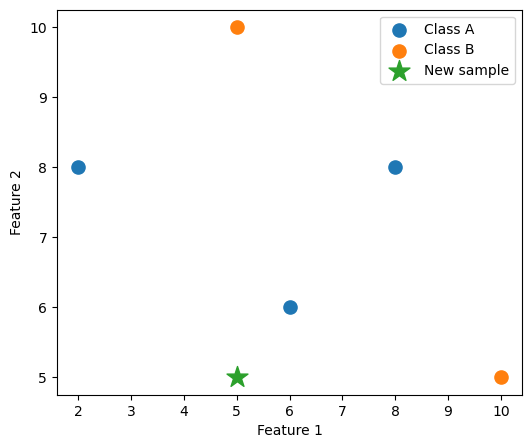

In [4]:
try:
    print(get_k_neighbors(X_generic, y_generic, sample_generic, k=3, metric='euclidean'))
except NotImplementedError as e:
    print('TODO in knn_manual.py ->', e)
plt.figure(figsize=(6,5))
for label in ['Class A','Class B']:
    m = y_generic == label
    plt.scatter(X_generic[m,0], X_generic[m,1], s=90, label=label)
plt.scatter(*sample_generic, marker='*', s=250, label='New sample')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2'); plt.legend(); plt.show()

# Mission 3 — Back to DNU case study

Tạo nhãn giảng dạy `Needs_Support = 1` nếu `Exam_Score < 65`, ngược lại là 0. Đây chỉ là nhãn giả lập phục vụ học tập, không phải quy định chính thức của DNU.

**Quan trọng:** không dùng `Exam_Score` làm feature vì sẽ gây target leakage.

**Trả lời:** Needs_Support được tạo trực tiếp từ điều kiện Exam_Score < 65. Nếu đưa Exam_Score vào X thì mô hình được nhìn thấy thông tin quyết định nhãn, làm đánh giá quá lạc quan và không phù hợp dự đoán trước kỳ thi. Các feature không cùng thang đo: Hours_Studied và Sleep_Hours tính bằng giờ, Attendance là tỷ lệ phần trăm, Previous_Scores là điểm. Biến có độ phân tán lớn có thể chi phối khoảng cách.

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError('Run: python scripts/download_data.py')
df = pd.read_csv(DATA_PATH).copy()
df['Needs_Support'] = (df['Exam_Score'] < 65).astype(int)
feature_cols = ['Hours_Studied','Attendance','Previous_Scores','Sleep_Hours']
assert 'Exam_Score' not in feature_cols
model_df = df[feature_cols + ['Needs_Support']].dropna().copy()
X = model_df[feature_cols]
y = model_df['Needs_Support']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
display(y.value_counts())

Train: (4955, 4) Test: (1652, 4)


Needs_Support
0    5155
1    1452
Name: count, dtype: int64

# Mission 4 — Baseline KNN: chưa scaling

Huấn luyện `KNeighborsClassifier` với `K=5`, Euclidean distance. Đọc accuracy, precision, recall và confusion matrix theo bối cảnh `Needs_Support`.

**Trả lời:** FN: sinh viên thực sự cần hỗ trợ (1) nhưng mô hình dự đoán không cần (0). FP: sinh viên không cần hỗ trợ (0) nhưng được dự đoán cần (1). Với mục tiêu không bỏ sót, FN đáng lo hơn vì người cần hỗ trợ có thể không nhận được can thiệp. Ưu tiên recall của lớp 1, đồng thời cân nhắc precision và nguồn lực hỗ trợ. Accuracy đo tỷ lệ đúng chung; precision là tỷ lệ thực sự cần hỗ trợ trong nhóm được báo động; recall là tỷ lệ được phát hiện trong nhóm thực sự cần hỗ trợ. Confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán: [[TN, FP], [FN, TP]].

**Kết quả thực nghiệm:** baseline chưa scaling đạt accuracy 86,56%, precision 70,92%, recall 65,84%. Confusion matrix: TN=1191, FP=98, FN=124, TP=239. Có 124/363 sinh viên thuộc lớp cần hỗ trợ bị bỏ sót.

KNN baseline — unscaled {'accuracy': 0.8656174334140436, 'precision': 0.7091988130563798, 'recall': 0.6584022038567493}


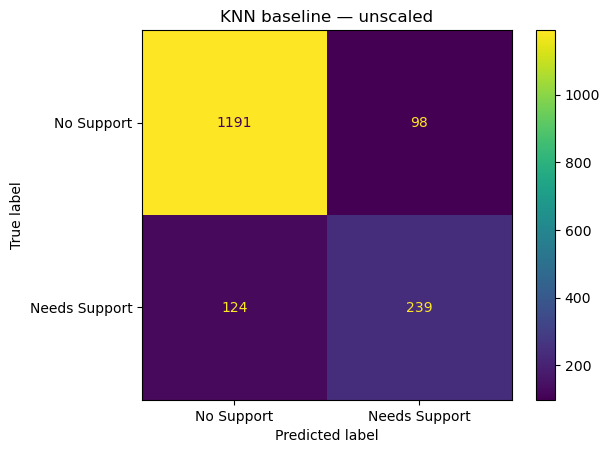

In [6]:
def evaluate(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    result = {'accuracy': accuracy_score(y_eval,pred), 'precision': precision_score(y_eval,pred,zero_division=0), 'recall': recall_score(y_eval,pred,zero_division=0)}
    print(name, result)
    ConfusionMatrixDisplay.from_predictions(y_eval, pred, display_labels=['No Support','Needs Support'])
    plt.title(name); plt.show()
    return result, pred
baseline_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
baseline_knn.fit(X_train, y_train)
baseline_result, baseline_pred = evaluate('KNN baseline — unscaled', baseline_knn, X_test, y_test)

# Mission 5 — Scaling matters

Fit `StandardScaler` **chỉ trên train set**, rồi so sánh mô hình trước/sau scaling. Quan trọng hơn: quan sát hàng xóm của cùng một sample có thay đổi không.

**Trả lời:** StandardScaler dùng z=(x−mean_train)/std_train để đo độ lệch theo đơn vị độ lệch chuẩn. Vì mỗi chiều được chia cho độ phân tán riêng, biến có thang số lớn không còn tự động chi phối khoảng cách. Thứ tự hàng xóm và dự đoán có thể đổi, nhưng scaling không bảo đảm mọi metric đều tốt hơn. Chỉ fit trên train; test chỉ transform để tránh rò rỉ thống kê.

**Quan sát:** sau scaling, accuracy 86,02%, precision 69,64%, recall 64,46%, đều giảm nhẹ so với baseline. Năm hàng xóm đổi từ [1277, 975, 492, 841, 1760] thành [1277, 3789, 841, 363, 2180] (vị trí trong tập train); chỉ hai hàng xóm chung. Dự đoán mẫu đầu vẫn là 0 ở cả hai mô hình. Điều này cho thấy hàng xóm có thể đổi mà nhãn chưa đổi.

,min,max,range
Hours_Studied,2,44,42
Attendance,60,100,40
Previous_Scores,50,100,50
Sleep_Hours,4,10,6


KNN — StandardScaler {'accuracy': 0.8601694915254238, 'precision': 0.6964285714285714, 'recall': 0.6446280991735537}


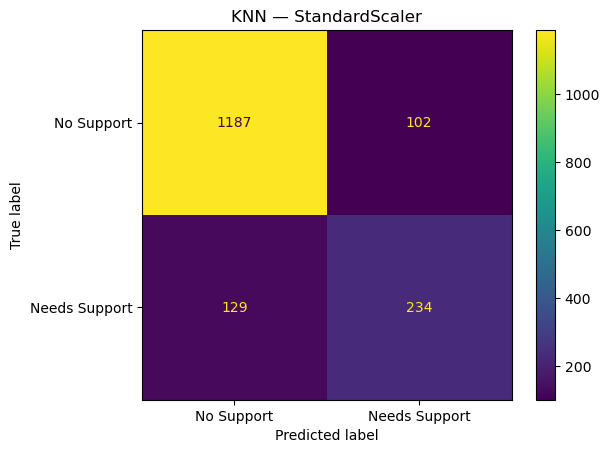

Raw neighbor train positions: [1277, 975, 492, 841, 1760]
Scaled neighbor train positions: [1277, 3789, 841, 363, 2180]
Prediction raw/scaled: 0 0


In [7]:
display(pd.DataFrame({'min':X_train.min(),'max':X_train.max(),'range':X_train.max()-X_train.min()}))
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
scaled_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
scaled_knn.fit(X_train_scaled, y_train)
scaled_result, scaled_pred = evaluate('KNN — StandardScaler', scaled_knn, X_test_scaled, y_test)
sample_raw = X_test.iloc[[0]]
sample_scaled = X_test_scaled[[0]]
raw_dist, raw_idx = baseline_knn.kneighbors(sample_raw, n_neighbors=5)
scaled_dist, scaled_idx = scaled_knn.kneighbors(sample_scaled, n_neighbors=5)
print('Raw neighbor train positions:', raw_idx[0].tolist())
print('Scaled neighbor train positions:', scaled_idx[0].tolist())
print('Prediction raw/scaled:', baseline_knn.predict(sample_raw)[0], scaled_knn.predict(sample_scaled)[0])

# Mission 6 — K and distance metric matter

Không dùng `GridSearchCV`. Thử thủ công `K ∈ {1,3,5,7,9}` và metric `euclidean`, `manhattan` trên dữ liệu đã scaling.

**Trả lời:** K tối ưu theo accuracy không nhất thiết tối ưu theo recall vì hai tiêu chí đo những mục tiêu khác nhau. K nhỏ nhạy với nhiễu và ranh giới cục bộ; K lớn làm ranh giới trơn hơn nhưng có thể bỏ sót lớp thiểu số. Nếu muốn không bỏ sót sinh viên cần hỗ trợ, ưu tiên recall lớp 1 và theo dõi precision. Bảng kết quả và các cấu hình tối ưu được in bên dưới. Việc thử trên test trong lab chỉ mang tính minh họa; khi chọn mô hình thực tế nên dùng validation hoặc cross-validation trên train và giữ test độc lập.

**Kết quả thực nghiệm:** K tốt nhất không giống nhau: accuracy cao nhất thuộc Manhattan, K=9 (87,17%, recall 64,46%); recall cao nhất thuộc Manhattan, K=7 (66,39%, accuracy 87,11%). Với mục tiêu giảm bỏ sót, trong 10 cấu hình thử nghiệm nên ưu tiên Manhattan, K=7.

,metric,k,accuracy,precision,recall
0,euclidean,1,0.827482,0.610169,0.595041
1,euclidean,3,0.849879,0.672673,0.617080
2,euclidean,5,0.860169,0.696429,0.644628
3,euclidean,7,0.862591,0.701183,0.652893
4,euclidean,9,0.868644,0.726708,0.644628
5,manhattan,1,0.832930,0.623229,0.606061
6,manhattan,3,0.851090,0.669565,0.636364
7,manhattan,5,0.862591,0.703593,0.647383
8,manhattan,7,0.871065,0.725904,0.663912
9,manhattan,9,0.871671,0.738170,0.644628


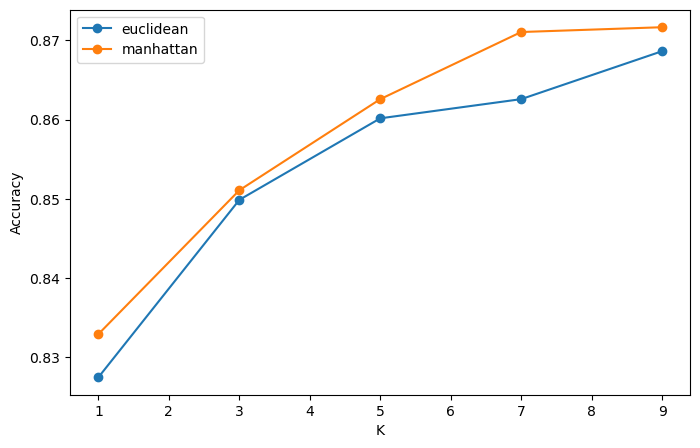

Best accuracy configurations:


,metric,k,accuracy,precision,recall
9,manhattan,9,0.871671,0.73817,0.644628


Best recall configurations:


,metric,k,accuracy,precision,recall
8,manhattan,7,0.871065,0.725904,0.663912


In [8]:
rows=[]
for metric in ['euclidean','manhattan']:
    for k in [1,3,5,7,9]:
        model=KNeighborsClassifier(n_neighbors=k, metric=metric)
        model.fit(X_train_scaled,y_train)
        pred=model.predict(X_test_scaled)
        rows.append({'metric':metric,'k':k,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0)})
results_df=pd.DataFrame(rows)
display(results_df)
plt.figure(figsize=(8,5))
for metric in ['euclidean','manhattan']:
    t=results_df[results_df.metric==metric]
    plt.plot(t.k,t.accuracy,marker='o',label=metric)
plt.xlabel('K'); plt.ylabel('Accuracy'); plt.legend(); plt.show()
print('Best accuracy configurations:')
display(results_df.loc[results_df.accuracy == results_df.accuracy.max()])
print('Best recall configurations:')
display(results_df.loc[results_df.recall == results_df.recall.max()])

# Transfer Challenge — KNN không chỉ dành cho Student Performance

Dùng Iris dataset có sẵn trong sklearn. Tự xây dựng pipeline: load → split → scaling → KNN → evaluation.

> **Những bước nào của KNN không thay đổi khi đối tượng chuyển từ sinh viên sang hoa?**

**Trả lời:** Các bước không đổi: biểu diễn đối tượng bằng vector đặc trưng, chia train/test, fit scaler trên train rồi transform cả hai tập, tính khoảng cách, chọn K hàng xóm, bỏ phiếu và đánh giá dự đoán trên test. Chỉ ý nghĩa đặc trưng và nhãn thay đổi: từ thông tin sinh viên sang số đo đài/cánh hoa và loài hoa.

**Kết quả Iris:** train 112 mẫu, test 38 mẫu; StandardScaler + KNN (K=5, Euclidean) dự đoán đúng 35/38 mẫu, accuracy 92,11%.

Iris shape: (150, 4) Classes: ['setosa' 'versicolor' 'virginica']
Train: (112, 4) Test: (38, 4)
Iris accuracy: 0.9210526315789473


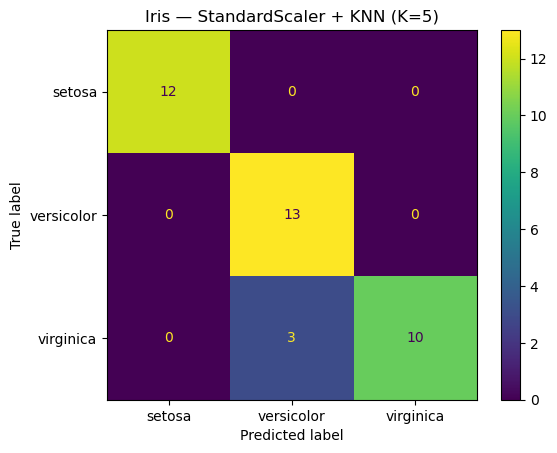

In [9]:
from sklearn.datasets import load_iris
from sklearn.pipeline import make_pipeline
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.25, random_state=42, stratify=y_iris)
iris_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, metric='euclidean'))
iris_knn.fit(Xi_train, yi_train)
y_iris_pred = iris_knn.predict(Xi_test)
print('Iris shape:', X_iris.shape, 'Classes:', iris.target_names)
print('Train:', Xi_train.shape, 'Test:', Xi_test.shape)
print('Iris accuracy:', accuracy_score(yi_test, y_iris_pred))
ConfusionMatrixDisplay.from_predictions(yi_test, y_iris_pred, display_labels=iris.target_names)
plt.title('Iris — StandardScaler + KNN (K=5)'); plt.show()

# Final — Model Reflection Card

## 1. KNN dự đoán như thế nào?
Tính khoảng cách từ mẫu mới đến các mẫu train, sắp xếp, chọn K điểm gần nhất rồi lấy nhãn chiếm đa số. Khi hòa phiếu, bản cài đặt thủ công ưu tiên nhãn có hàng xóm gần nhất; nếu khoảng cách bằng nhau, thứ tự index quyết định.

## 2. Ba yếu tố làm prediction thay đổi
- **K:** thay đổi số người bỏ phiếu; K nhỏ nhạy nhiễu, K lớn có thể làm mất cấu trúc cục bộ và thiên về lớp đông.
- **Distance metric:** thay đổi cách đo độ gần; ví dụ Euclidean chọn A/B/C và dự đoán Class A, Manhattan chọn A/D/E và dự đoán Class B.
- **Feature scaling:** điều chỉnh đóng góp của từng chiều vào khoảng cách nên có thể thay đổi hàng xóm và nhãn dự đoán.

## 3. Trong case study Needs_Support, lỗi nào đáng lo hơn?
FN đáng lo hơn với mục tiêu không bỏ sót: sinh viên cần hỗ trợ lại được dự đoán không cần. Vì thế ưu tiên recall lớp 1, đồng thời xem precision và khả năng hỗ trợ thực tế. Nhãn này chỉ phục vụ bài học.

## 4. Vì sao Exam_Score không được dùng làm feature?
Nhãn được định nghĩa bằng ngưỡng của chính Exam_Score, nên sử dụng điểm thi đầu vào làm lộ thông tin mục tiêu và không phù hợp dự đoán trước khi có điểm thi.

## 5. Một câu chốt
KNN không phải thuật toán dành riêng cho sinh viên vì nó áp dụng cho bất kỳ đối tượng nào được biểu diễn bằng đặc trưng và có một cách đo khoảng cách phù hợp, như phân loại loài hoa Iris.


## Trước khi push

```bash
python tests/check_lab02.py
python -m pytest -q tests/test_knn_manual.py
git add .
git commit -m "Complete Lab 02 KNN"
git push
```

Kiểm tra tab **Actions** và đảm bảo workflow `Lab 02 Check` chạy thành công sau khi hoàn thiện bài.